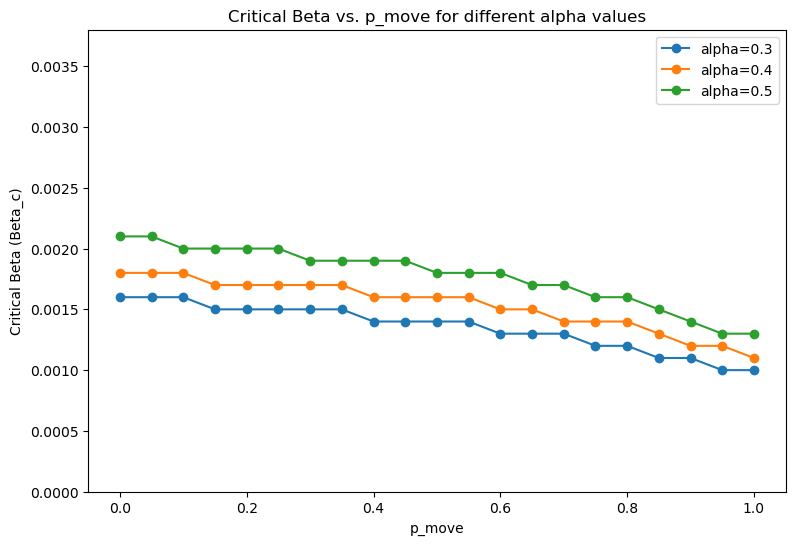

In [18]:
import numpy as np 
import networkx as nx
import matplotlib.pyplot as plt
import random
import pandas as pd

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_small_world_network(N, k, p_rewire):
    G = nx.watts_strogatz_graph(N, k, p_rewire)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.full(N, 100)
    average_degrees = n * 0.1
    return n, average_degrees

# 运行模拟实验并找到临界阈值beta_c
def find_critical_beta(N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps, beta_values):
    for beta in beta_values:
        rho = np.full(N, initial_infected_density)
        for t in range(steps):
            new_rho = np.zeros(N)
            R_i = np.zeros(N)
            D_i = np.zeros(N)
            P_i = np.zeros(N)
            Pi_i = np.zeros(N)
            for i in range(N):
                R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                         np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
                D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] * 0.9  +
                                         np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
                P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
            for i in range(N):
                Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
                new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
            rho = new_rho
        
        # 如果感染比例大幅增加，认为找到了临界beta_c
        if np.mean(rho) > 0.01:  # 可根据需要调整阈值
            return beta
    return beta_values[-1]  # 若没找到临界点，返回最大beta值

# 初始变量
N = 50
k = 4
p_rewire = 0.8
initial_infected_density = 0.01
mu = 0.1
steps = 200

# 方法一：生成小世界网络
W = generate_small_world_network(N, k, p_rewire)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)

# 方法四：生成不同区间的 beta 值
beta_values = np.concatenate([
    np.arange(0.0003, 0.001, 0.0002),
    np.arange(0.001, 0.003, 0.0001),
    np.arange(0.003, 0.004, 0.0002)
])

# 不同的移动概率值
p_move_values = np.arange(0.0, 1.05, 0.05)

# 不同的alpha值
alpha_values = [0.3, 0.4, 0.5]

# 记录不同alpha和p_move值下的结果
all_results = {}

for alpha in alpha_values:
    for p_move in p_move_values:
        beta_c_values = []
        for _ in range(10):  # 平均运行多次
            beta_c = find_critical_beta(N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps, beta_values)
            beta_c_values.append(beta_c)
        average_beta_c = np.mean(beta_c_values)
        all_results[(alpha, p_move)] = average_beta_c

# 绘制结果
plt.figure(figsize=(9, 6))
for alpha in alpha_values:
    results = [all_results[(alpha, p)] for p in p_move_values]
    plt.plot(p_move_values, results, marker='o', label=f'alpha={alpha}')
plt.xlabel('p_move')
plt.ylabel('Critical Beta (Beta_c)')
plt.yscale("linear")
plt.ylim(0, max(beta_values))  # 设置y轴范围
plt.title('Critical Beta vs. p_move for different alpha values')
plt.legend()
plt.show()
